# Landing Page A/B Test: Should We Ship the New Page?

An e-commerce site tested a **new landing page** (treatment) against the **old page** (control) for three weeks.
The metric is **conversion** (0/1 per user).

**Decision to make**: ship the new page, keep the old one, or keep testing?

**Analysis plan** (fixed before looking at the results)

| Step | Question |
|---|---|
| 1. Data quality | Can each row be trusted? Did users see the page they were assigned to? |
| 2. Design checks | Was the traffic split really 50/50 (sample ratio mismatch)? Did the test run long enough? |
| 3. Power | How small an effect could this experiment detect? |
| 4. Primary analysis | Two-sided two-proportion z-test at alpha = 0.05, with a 95% confidence interval for the difference |
| 5. Robustness | Sensitivity to cleaning rules, novelty effect, segments (with multiple-testing correction), the cost of peeking |
| 6. Bayesian view | Probability the new page is better, and the expected loss of each decision |
| 7. Decision | Recommendation and next steps |

The statistics come from `src/abtest/stats.py`, implemented with numpy / scipy and covered by unit tests (`tests/test_stats.py`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from abtest import stats

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
ALPHA = 0.05

raw = pd.read_csv(ROOT / "data" / "raw" / "ab_data.csv", parse_dates=["timestamp"])
print(f"{len(raw):,} rows, {raw.user_id.nunique():,} unique users, "
      f"{raw.timestamp.min():%Y-%m-%d} to {raw.timestamp.max():%Y-%m-%d}")
raw.head()

294,478 rows, 290,584 unique users, 2017-01-02 to 2017-01-24


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


## 1. Data quality

Two things must hold for a clean comparison: every user is in exactly one group, and every user saw the page that belongs to their group.

In [2]:
print("Missing values:", int(raw.isna().sum().sum()))
display(pd.crosstab(raw.group, raw.landing_page, margins=True))

mismatch = (raw.group == "treatment") != (raw.landing_page == "new_page")
dup_users = raw.user_id[raw.user_id.duplicated(keep=False)].nunique()
print(f"Rows where group and page disagree: {mismatch.sum():,} ({mismatch.mean():.2%})")
print(f"Users appearing more than once:     {dup_users:,}")
print(f"...of which have a mismatched row:  {raw.loc[mismatch, 'user_id'].isin(raw.user_id[raw.user_id.duplicated(keep=False)]).sum():,}")

Missing values: 0


landing_page,new_page,old_page,All
group,,,
control,1928,145274,147202
treatment,145311,1965,147276
All,147239,147239,294478


Rows where group and page disagree: 3,893 (1.32%)
Users appearing more than once:     3,894
...of which have a mismatched row:  3,893


**Findings**
- No missing values.
- **3,893 rows (1.3%) are inconsistent**: the user is labelled `treatment` but saw the old page, or `control` but saw the new page. We cannot tell which label is right, so these rows cannot be attributed to either variant.
- 3,894 users appear twice. All but one of them are exactly the users with an inconsistent row, so the duplicates are the same logging problem seen from another angle. The one remaining user has two consistent treatment rows.

**Cleaning rule**: drop the inconsistent rows, then keep each user's first exposure. Section 5 checks that the conclusion does not depend on this choice.

In [3]:
df = (raw[~mismatch]
      .sort_values("timestamp")
      .drop_duplicates("user_id", keep="first")
      .assign(date=lambda d: d.timestamp.dt.floor("D"),
              week=lambda d: ((d.timestamp - d.timestamp.min()).dt.days // 7) + 1,
              day_type=lambda d: np.where(d.timestamp.dt.day_of_week >= 5, "Weekend", "Weekday"),
              daypart=lambda d: pd.cut(d.timestamp.dt.hour, [-1, 5, 11, 17, 23],
                                       labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-17)", "Evening (18-23)"])))
print(f"Clean dataset: {len(df):,} users ({len(raw) - len(df):,} rows removed, {(len(raw) - len(df)) / len(raw):.2%})")

summary = df.groupby("group").converted.agg(users="count", conversions="sum", rate="mean")
summary

Clean dataset: 290,584 users (3,894 rows removed, 1.32%)


,users,conversions,rate
group,,,
control,145274,17489,0.1204
treatment,145310,17264,0.1188


## 2. Design checks

### Sample ratio mismatch (SRM)
If the intended split is 50/50 but the observed split is not, assignment or logging is broken and the comparison is biased, no matter what the conversion rates say. This is checked with a chi-square goodness-of-fit test; the usual alarm threshold is p < 0.001.

Control 145,274 vs treatment 145,310 (50.006% in treatment)
SRM test: chi2 = 0.0045, p = 0.947 -> no evidence of a mismatch


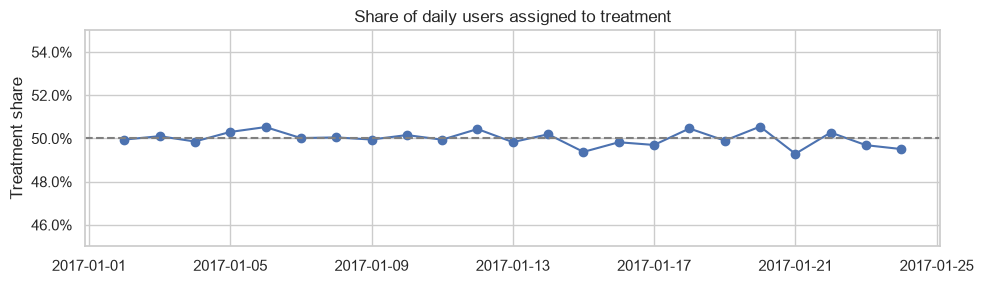

Test duration: 22 days, Jan 02 to Jan 24 (23 calendar dates)


In [4]:
n_c, n_t = summary.loc["control", "users"], summary.loc["treatment", "users"]
x_c, x_t = summary.loc["control", "conversions"], summary.loc["treatment", "conversions"]
chi2, p_srm = stats.srm_test(n_c, n_t)
print(f"Control {n_c:,} vs treatment {n_t:,} ({n_t / (n_c + n_t):.3%} in treatment)")
print(f"SRM test: chi2 = {chi2:.4f}, p = {p_srm:.3f} -> {'no evidence of a mismatch' if p_srm > 0.001 else 'MISMATCH'}")

daily = df.groupby(["date", "group"]).converted.agg(users="count", rate="mean").unstack()
share = daily["users"]["treatment"] / daily["users"].sum(axis=1)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(share.index, share.values, marker="o")
ax.axhline(0.5, color="grey", ls="--")
ax.set_ylim(0.45, 0.55); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Share of daily users assigned to treatment"); ax.set_ylabel("Treatment share")
plt.tight_layout(); plt.savefig(FIG / "01_daily_split.png", dpi=150); plt.show()
print(f"Test duration: {round((df.timestamp.max() - df.timestamp.min()).total_seconds() / 86400)} days, "
      f"{df.timestamp.min():%b %d} to {df.timestamp.max():%b %d} ({df.date.nunique()} calendar dates)")

**Findings**
- The split is 50.0% / 50.0% (SRM p = 0.95) and stays close to 50% every day: assignment looks healthy.
- The test ran for 22 days (Jan 2 to Jan 24), covering three full weekly cycles, so weekday and weekend behaviour are both well represented.

## 3. Power: what could this experiment detect?

A non-significant result only means something if the test was able to detect an effect that matters. The minimum detectable effect (MDE) is the smallest true difference the test would find 80% of the time.

Baseline conversion: 12.04%, users per group: 145,274
MDE at 80% power: 0.34 percentage points (2.8% relative)


,relative lift,absolute lift (pp),users needed per group,power with this sample
0,0.5%,0.0602,4597781,0.0719
1,1.0%,0.1204,1151917,0.1673
2,2.0%,0.2408,289213,0.5102
3,3.0%,0.3612,129087,0.8443
4,5.0%,0.6019,46864,0.9985
5,10.0%,1.2039,11960,1.0000


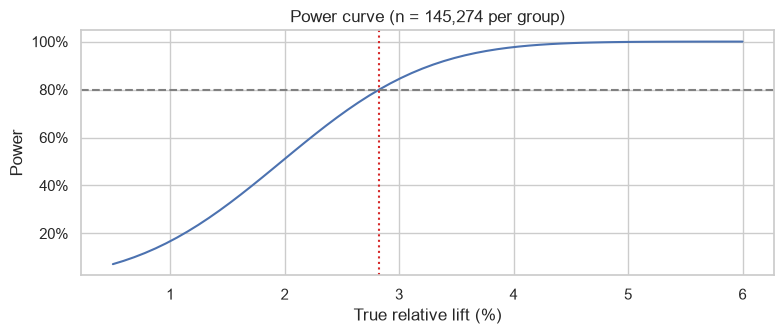

In [5]:
p_base = summary.loc["control", "rate"]
n = int(min(n_c, n_t))
mde = stats.minimum_detectable_effect(p_base, n, alpha=ALPHA, power=0.8)
print(f"Baseline conversion: {p_base:.2%}, users per group: {n:,}")
print(f"MDE at 80% power: {mde * 100:.2f} percentage points ({mde / p_base:.1%} relative)")

lifts = np.array([0.005, 0.01, 0.02, 0.03, 0.05, 0.10])
table = pd.DataFrame({
    "relative lift": [f"{l:.1%}" for l in lifts],
    "absolute lift (pp)": lifts * p_base * 100,
    "users needed per group": [stats.sample_size_per_group(p_base, l * p_base) for l in lifts],
    "power with this sample": [stats.power_of_test(p_base, l * p_base, n) for l in lifts],
})
display(table)

grid = np.linspace(0.005, 0.06, 60)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(grid * 100, [stats.power_of_test(p_base, g * p_base, n) for g in grid])
ax.axhline(0.8, color="grey", ls="--"); ax.axvline(mde / p_base * 100, color="tab:red", ls=":")
ax.set_xlabel("True relative lift (%)"); ax.set_ylabel("Power")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title(f"Power curve (n = {n:,} per group)")
plt.tight_layout(); plt.savefig(FIG / "02_power_curve.png", dpi=150); plt.show()

**Findings**
- With ~145K users per group the test can detect an absolute change of **0.34 percentage points (2.8% relative)** with 80% power.
- A 5% relative lift would be detected with near certainty; a 1% lift would need about 1.1 million users per group, far more than this test has.
- So this is a well-powered test for effects of roughly 3% and above. If the new page had a meaningful advantage of that size, we would very likely see it.

## 4. Primary analysis

- H0: the conversion rates of the two pages are equal
- H1: they differ (two-sided, because a worse page is as important to detect as a better one)

Control:   12.039%  (17,489 / 145,274)
Treatment: 11.881%  (17,264 / 145,310)
Difference: -0.158 pp  (relative -1.31%)
95% CI for the difference: [-0.394, +0.078] pp
z = -1.311, p = 0.190


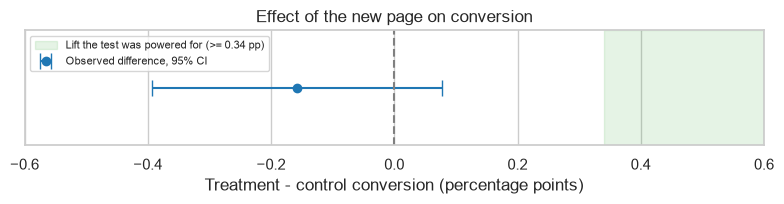

In [6]:
res = stats.two_proportion_ztest(x_c, n_c, x_t, n_t, alpha=ALPHA)
print(f"Control:   {res.rate_control:.3%}  ({x_c:,} / {n_c:,})")
print(f"Treatment: {res.rate_treatment:.3%}  ({x_t:,} / {n_t:,})")
print(f"Difference: {res.diff_abs * 100:+.3f} pp  (relative {res.lift_rel:+.2%})")
print(f"95% CI for the difference: [{res.ci_low * 100:+.3f}, {res.ci_high * 100:+.3f}] pp")
print(f"z = {res.z:.3f}, p = {res.p_value:.3f}")

fig, ax = plt.subplots(figsize=(8, 2.2))
ax.errorbar(res.diff_abs * 100, 0, xerr=[[(res.diff_abs - res.ci_low) * 100], [(res.ci_high - res.diff_abs) * 100]],
            fmt="o", capsize=6, color="tab:blue", label="Observed difference, 95% CI")
ax.axvline(0, color="grey", ls="--")
ax.axvspan(mde * 100, 0.6, color="tab:green", alpha=0.12, label=f"Lift the test was powered for (>= {mde*100:.2f} pp)")
ax.set_xlim(-0.6, 0.6); ax.set_yticks([]); ax.set_xlabel("Treatment - control conversion (percentage points)")
ax.legend(loc="upper left", fontsize=8); ax.set_title("Effect of the new page on conversion")
plt.tight_layout(); plt.savefig(FIG / "03_effect_ci.png", dpi=150); plt.show()

**Findings**
- The new page converts at **11.88%** vs **12.04%** for the old page: a difference of **-0.16 pp** (-1.3% relative).
- p = 0.19, so the difference is not statistically significant: we cannot say the pages differ.
- The confidence interval is the more useful result: the true effect is plausibly between **-0.39 pp and +0.08 pp**. The data therefore rule out any lift larger than +0.08 pp (+0.6% relative). Even in the best case the new page is essentially no better than the old one.
- "Not significant" here does not mean "we don't know": the test was powered for a 0.34 pp change, and the whole interval lies below that.

## 5. Robustness checks

### 5.1 Does the cleaning rule matter?
The inconsistent rows were dropped in section 1. The same test is repeated under two alternative rules.

In [7]:
def run(frame, by):
    g = frame.groupby(by).converted.agg(["sum", "count"])
    a, b = g.index[0], g.index[1]
    r = stats.two_proportion_ztest(g.loc[a, "sum"], g.loc[a, "count"], g.loc[b, "sum"], g.loc[b, "count"])
    return {"control users": g.loc[a, "count"], "treatment users": g.loc[b, "count"],
            "control rate": r.rate_control, "treatment rate": r.rate_treatment,
            "diff (pp)": r.diff_abs * 100, "CI low (pp)": r.ci_low * 100, "CI high (pp)": r.ci_high * 100,
            "p-value": r.p_value}

first_seen = raw.sort_values("timestamp").drop_duplicates("user_id", keep="first")
by_page = first_seen.assign(page=first_seen.landing_page.map({"old_page": "0 old_page", "new_page": "1 new_page"}))
sensitivity = pd.DataFrame({
    "Primary: drop inconsistent rows": run(df, "group"),
    "By assigned group (keep all users)": run(first_seen, "group"),
    "By page actually seen (keep all users)": run(by_page, "page"),
}).T
sensitivity

,control users,treatment users,control rate,treatment rate,diff (pp),CI low (pp),CI high (pp),p-value
Primary: drop inconsistent rows,"145,274.0000","145,310.0000",0.1204,0.1188,-0.1578,-0.3938,0.0781,0.1899
By assigned group (keep all users),"145,294.0000","145,290.0000",0.1204,0.1188,-0.1587,-0.3946,0.0773,0.1876
By page actually seen (keep all users),"145,293.0000","145,291.0000",0.1205,0.1187,-0.1781,-0.4141,0.0579,0.1391


**Finding**: all three rules give the same answer. The difference stays between -0.18 and -0.16 pp, every interval includes zero and no upper bound exceeds +0.08 pp. The conclusion does not depend on how the 1.3% of inconsistent rows are handled.

### 5.2 Novelty effect: does the difference change over time?
Returning users sometimes react to a redesign at first (curiosity or confusion), and the effect fades. If that were happening, the daily difference would trend over the test.

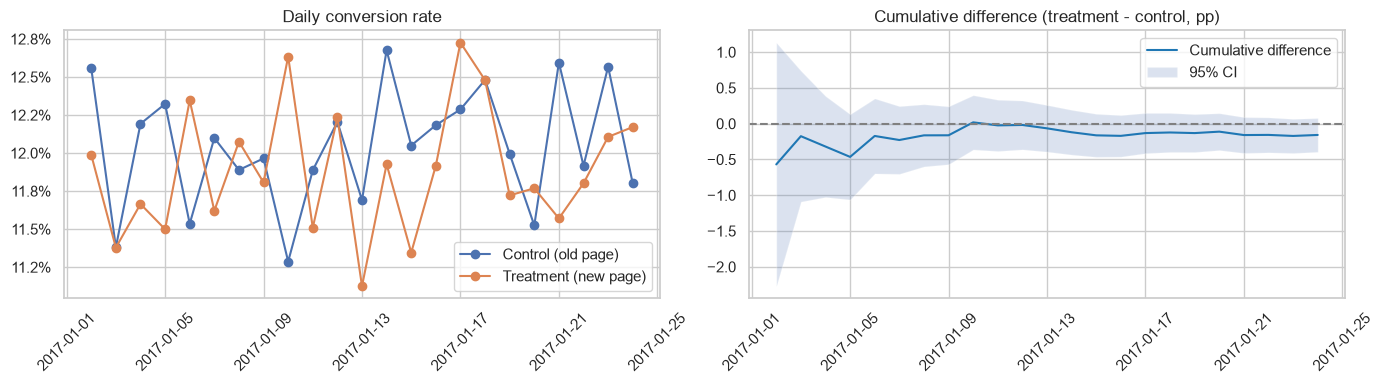

,control users,treatment users,control rate,treatment rate,diff (pp),p-value
Week 1,"46,069.0000","46,377.0000",0.1194,0.1176,-0.1720,0.4185
Week 2,"46,340.0000","46,215.0000",0.1195,0.1179,-0.1667,0.4329
Week 3,"46,247.0000","46,222.0000",0.1221,0.1207,-0.1383,0.5195
Week 4,"6,618.0000","6,496.0000",0.1215,0.1202,-0.1259,0.8250


In [8]:
rates = daily["rate"]
cum = df.sort_values("timestamp").groupby(["date", "group"]).converted.agg(["sum", "count"]).unstack().cumsum()
cum_diff, lo, hi, pvals = [], [], [], []
for d in cum.index:
    r = stats.two_proportion_ztest(cum.loc[d, ("sum", "control")], cum.loc[d, ("count", "control")],
                                   cum.loc[d, ("sum", "treatment")], cum.loc[d, ("count", "treatment")])
    cum_diff.append(r.diff_abs * 100); lo.append(r.ci_low * 100); hi.append(r.ci_high * 100); pvals.append(r.p_value)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(rates.index, rates["control"], marker="o", label="Control (old page)")
axes[0].plot(rates.index, rates["treatment"], marker="o", label="Treatment (new page)")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
axes[0].set_title("Daily conversion rate"); axes[0].legend()
axes[1].plot(cum.index, cum_diff, color="tab:blue", label="Cumulative difference")
axes[1].fill_between(cum.index, lo, hi, alpha=0.2, label="95% CI")
axes[1].axhline(0, color="grey", ls="--")
axes[1].set_title("Cumulative difference (treatment - control, pp)"); axes[1].legend()
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(FIG / "04_over_time.png", dpi=150); plt.show()

weekly = pd.DataFrame({f"Week {w}": run(g, "group") for w, g in df.groupby("week")}).T
weekly[["control users", "treatment users", "control rate", "treatment rate", "diff (pp)", "p-value"]]

**Findings**
- Daily rates of the two pages cross repeatedly with no trend; the cumulative difference settles slightly below zero and its interval narrows around it.
- By week, the difference is between -0.17 and -0.13 pp in every week and never significant (week 4 only has the last two days). There is no sign of a novelty effect in either direction, so waiting longer is unlikely to change the picture.

### 5.3 Segments: does the new page work for some users?
A flat overall result can hide a segment where the new page wins. The dataset has no user attributes, so the only segments available are based on visit time. Looking at many segments inflates false positives, so p-values are adjusted with the Holm method.

,control users,treatment users,control rate,treatment rate,diff (pp),CI low (pp),CI high (pp),p-value,Holm-adjusted p
day_type: Weekday,"105,376.0000","105,624.0000",0.1198,0.1194,-0.0366,-0.3135,0.2403,0.7954,1.0000
day_type: Weekend,"39,898.0000","39,686.0000",0.1220,0.1172,-0.4791,-0.9300,-0.0281,0.0373,0.2240
daypart: Night (0-5),"36,234.0000","36,369.0000",0.1182,0.1143,-0.3876,-0.8538,0.0787,0.1033,0.5164
daypart: Morning (6-11),"36,442.0000","36,141.0000",0.1224,0.1186,-0.3768,-0.8504,0.0968,0.1190,0.5164
daypart: Afternoon (12-17),"36,118.0000","36,634.0000",0.1212,0.1199,-0.1325,-0.6057,0.3407,0.5831,1.0000
daypart: Evening (18-23),"36,480.0000","36,166.0000",0.1198,0.1225,0.2671,-0.2074,0.7417,0.2698,0.8095


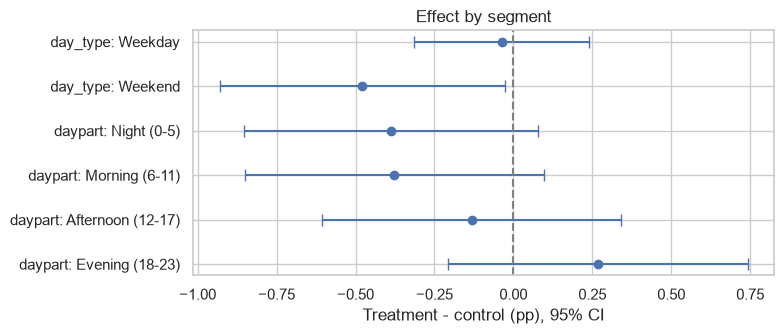

In [9]:
rows = {}
for col in ["day_type", "daypart"]:
    for level, g in df.groupby(col, observed=True):
        rows[f"{col}: {level}"] = run(g, "group")
seg = pd.DataFrame(rows).T
seg["Holm-adjusted p"] = stats.holm_adjust(seg["p-value"].tolist())
display(seg[["control users", "treatment users", "control rate", "treatment rate", "diff (pp)",
             "CI low (pp)", "CI high (pp)", "p-value", "Holm-adjusted p"]])

fig, ax = plt.subplots(figsize=(8, 3.5))
y = np.arange(len(seg))[::-1]
ax.errorbar(seg["diff (pp)"], y, xerr=[seg["diff (pp)"] - seg["CI low (pp)"], seg["CI high (pp)"] - seg["diff (pp)"]],
            fmt="o", capsize=4)
ax.axvline(0, color="grey", ls="--"); ax.set_yticks(y); ax.set_yticklabels(seg.index)
ax.set_xlabel("Treatment - control (pp), 95% CI"); ax.set_title("Effect by segment")
plt.tight_layout(); plt.savefig(FIG / "05_segments.png", dpi=150); plt.show()

**Findings**
- Weekend visitors show a nominally significant drop (-0.48 pp, p = 0.037). After the Holm correction for six comparisons the adjusted p-value is 0.22, so this is not reliable evidence: with six segments, one p-value below 0.05 is expected by chance about a quarter of the time. Reporting it as a finding would be a textbook case of p-hacking.
- Evening is the only segment with a positive point estimate (+0.27 pp), and its interval comfortably includes zero.
- No segment justifies a targeted rollout. These segments are exploratory; a proper segment analysis needs user attributes (new vs returning, device, traffic source), which this dataset does not have.

### 5.4 Why the result should not be checked every day
A common mistake is to look at the p-value daily and stop as soon as it drops below 0.05. The simulation below runs A/A tests (no true difference) and counts how often at least one interim look is "significant".

,number of looks,false positive rate
0,1,0.0494
1,2,0.0862
2,5,0.1408
3,10,0.1862
4,22,0.2612


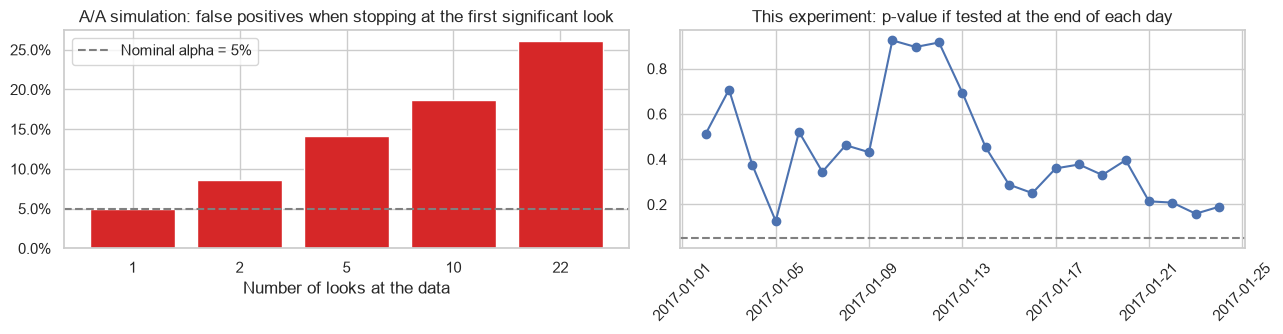

Days on which the cumulative p-value was below 0.05: 0 of 23


In [10]:
looks = [1, 2, 5, 10, 22]
fpr = [stats.peeking_false_positive_rate(p_base, n, k, alpha=ALPHA, n_sims=5000, seed=1) for k in looks]
peek = pd.DataFrame({"number of looks": looks, "false positive rate": fpr})
display(peek)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].bar([str(k) for k in looks], fpr, color="tab:red")
axes[0].axhline(ALPHA, color="grey", ls="--", label="Nominal alpha = 5%")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_xlabel("Number of looks at the data"); axes[0].set_title("A/A simulation: false positives when stopping at the first significant look")
axes[0].legend()
axes[1].plot(cum.index, pvals, marker="o"); axes[1].axhline(ALPHA, color="grey", ls="--")
axes[1].set_title("This experiment: p-value if tested at the end of each day"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(FIG / "06_peeking.png", dpi=150); plt.show()
print(f"Days on which the cumulative p-value was below 0.05: {sum(p < ALPHA for p in pvals)} of {len(pvals)}")

**Findings**
- With a single planned analysis the false positive rate is ~5%, as designed. Checking daily for 22 days and stopping at the first significant result pushes it to about 26%: roughly one in four tests of two identical pages would be declared a "win" or "loss".
- In this experiment the cumulative p-value never dropped below 0.05 on any day, so the conclusion would have been the same at every look.
- This is why the analysis above uses one test at the planned end of the experiment. Teams that need to monitor results continuously should use a sequential method (for example alpha spending or always-valid p-values).

## 6. Bayesian view

The frequentist test answers "how surprising is this data if the pages are equal?". Decision makers usually ask something else: "how likely is it that the new page is better, and what do we lose if we are wrong?". A Beta-Binomial model with a flat Beta(1, 1) prior answers that directly.

In [11]:
bayes = stats.bayesian_ab(x_c, n_c, x_t, n_t)
print(f"P(new page is better)          = {bayes.prob_treatment_better:.1%}")
print(f"95% credible interval, rel lift = [{bayes.lift_ci_low:+.2%}, {bayes.lift_ci_high:+.2%}]")
print(f"Expected loss if we ship new    = {bayes.expected_loss_treatment * 100:.3f} pp of conversion")
print(f"Expected loss if we keep old    = {bayes.expected_loss_control * 100:.4f} pp of conversion")

P(new page is better)          = 9.5%
95% credible interval, rel lift = [-3.23%, +0.66%]
Expected loss if we ship new    = 0.163 pp of conversion
Expected loss if we keep old    = 0.0054 pp of conversion


**Findings**
- There is only a **~10% probability** that the new page is better than the old one.
- Shipping the new page has an expected cost of 0.16 pp of conversion; keeping the old page has an expected cost about 30 times smaller. Both views point the same way.

## 7. Decision

**Recommendation: do not ship the new landing page. Keep the old page and stop this test.**

| Evidence | Result |
|---|---|
| Experiment validity | Split is 50/50 (SRM p = 0.95); 1.3% inconsistent rows removed, conclusion unchanged under other cleaning rules |
| Effect | -0.16 pp (11.88% vs 12.04%), p = 0.19 |
| Best case | 95% CI upper bound is +0.08 pp (+0.6% relative), far below the 0.34 pp the test was powered to detect |
| Probability the new page is better | ~10% |
| Novelty or segment effects | None found (one nominal segment result does not survive multiple-testing correction) |

**Why not keep testing?** The test already has 145K users per group and three full weeks. Detecting a lift as small as the best case here (+0.6% relative) would need millions of users per group, and such a small lift would rarely justify the cost of a redesign.

**Next steps**
1. Fix the logging issue that produced the 3,893 inconsistent rows before the next experiment.
2. Find out *why* the new page does not convert better with funnel and click data (where do users drop off on each page?) and user research, then test a new variant built on those findings.
3. Record the decision rule, sample size and duration before the next test starts, and analyse it once at the planned end (or use a sequential design if early stopping is required).

**Limitations**: the dataset has no user attributes, revenue or business context, so the analysis covers conversion only and the segments are limited to visit time. A real decision would also weigh revenue per user and long-term retention.